In [ ]:
!pip install networkx pyvis matplotlib

In [2]:
import json

# Load JSON file with 'utf-8-sig' encoding to handle the BOM
with open('pubmed_graph_kw_small.json', 'r', encoding='utf-8-sig') as file:
    data = json.load(file)

# Extract nodes and relationships from JSON
nodes = data['network']['items']
relationships = data['network']['links']

# Generate Cypher scripts for nodes
def create_node(node):
    return f"CREATE (n:Keyword {{id: {node['id']}, label: '{node['label']}', x: {node['x']}, y: {node['y']}, cluster: {node['cluster']}, links: {node['weights']['Links']}, total_link_strength: {node['weights']['Total link strength']}, occurrences: {node['weights']['Occurrences']}, avg_pub_year: {node['scores']['Avg. pub. year']}}});"

# Generate Cypher scripts for relationships
def create_relationship(relationship):
    return f"MATCH (a:Keyword {{id: {relationship['source_id']}}}), (b:Keyword {{id: {relationship['target_id']}}}) CREATE (a)-[:RELATED_TO {{strength: {relationship['strength']}}}]->(b);"

# Write Cypher queries to a file
with open('neo4j_import.cypher', 'w') as cypher_file:
    # Create nodes
    for node in nodes:
        cypher_file.write(create_node(node) + "\n")
    
    # Create relationships
    for relationship in relationships:
        cypher_file.write(create_relationship(relationship) + "\n")

print("Cypher queries have been written to 'neo4j_import.cypher'. Open the file and copy the cypher commands into neo4j")


Cypher queries have been written to 'neo4j_import.cypher'. Open the file and copy the cypher commands into neo4j


network_visualization.html


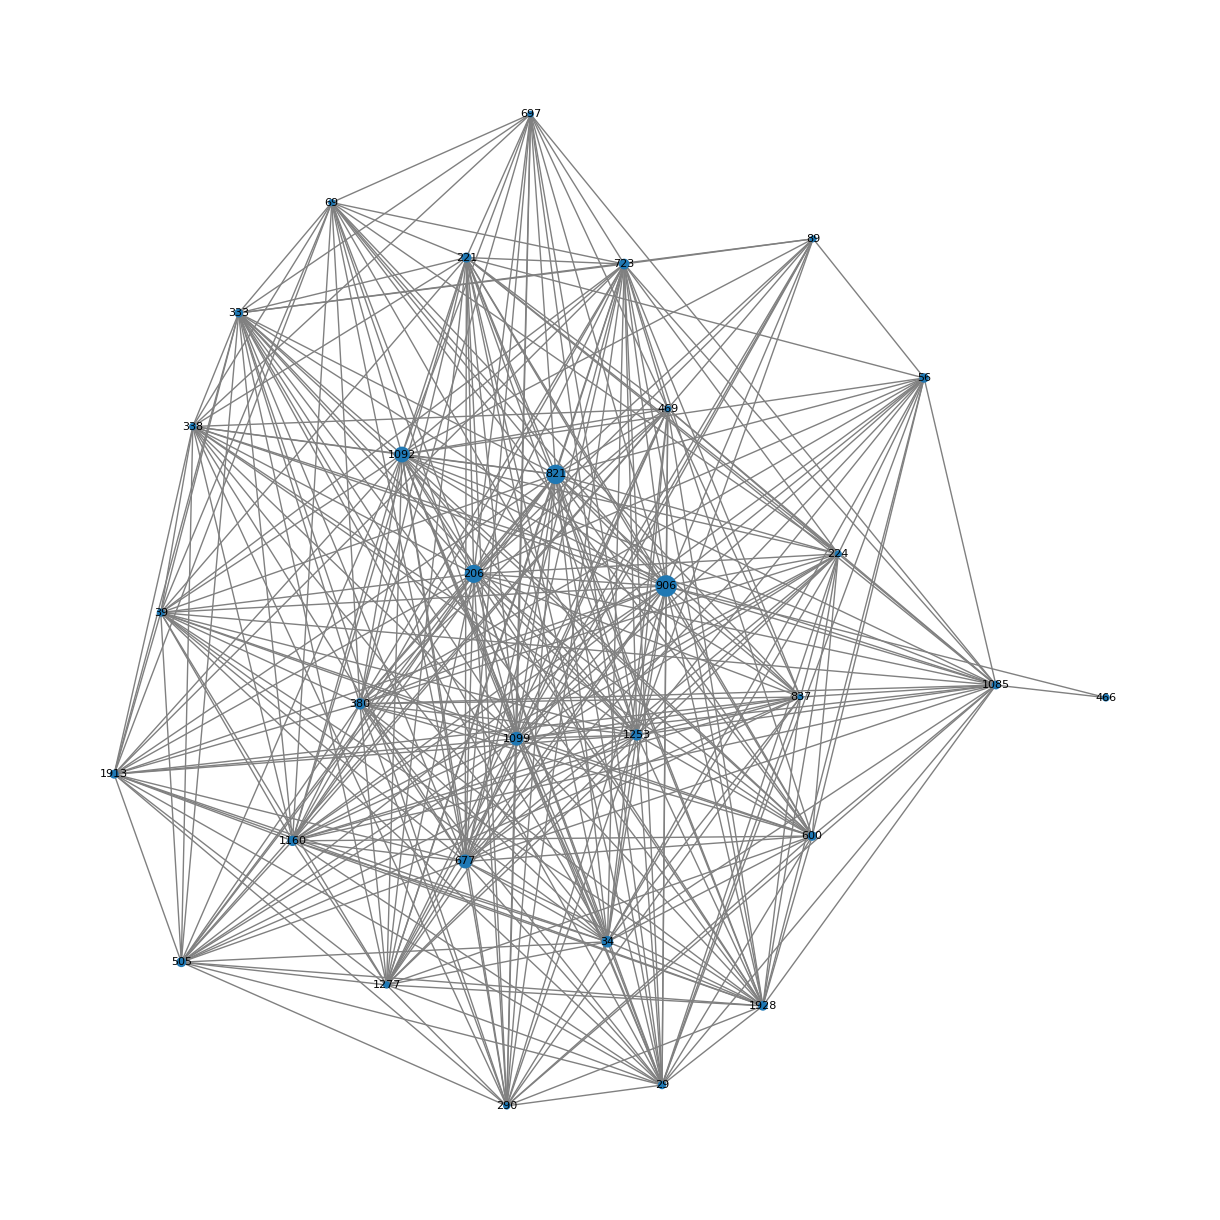

In [10]:
import json
import networkx as nx
from pyvis.network import Network
import matplotlib.pyplot as plt

# Load JSON data
json_file = "pubmed_graph_kw_small.json"
with open(json_file, "r", encoding="utf-8-sig") as f:
    data = json.load(f)

# Create a graph
G = nx.Graph()

# Add nodes with dynamic size based on occurrences
for item in data["network"]["items"]:
    size = item["weights"]["Occurrences"] * 1.25  # Scale occurrences for better visualization
    G.add_node(item["id"], label=item["label"], cluster=item["cluster"], x=item["x"], y=item["y"], size=size, occurrences=item["weights"]["Occurrences"], pub_year=item["scores"]["Avg. pub. year"])

# Add edges
for link in data["network"]["links"]:
    G.add_edge(link["source_id"], link["target_id"], weight=link["strength"])

# Create an interactive network using Pyvis
net = Network(notebook=True, height="1500px", width="100%", bgcolor="#222222", font_color="white", cdn_resources="in_line")

# Add nodes with dynamic size
for node, data in G.nodes(data=True):
    net.add_node(node, label=data["label"], size=data["size"], title=f"Occurrences: {data['occurrences']}, Avg. Pub. Year: {data['pub_year']}")

# Add edges
for edge in G.edges(data=True):
    net.add_edge(edge[0], edge[1], value=edge[2]["weight"])

# Stabilize layout and set fixed edge length
net.force_atlas_2based(gravity=-50, central_gravity=0.02, spring_length=200, spring_strength=0.08, damping=0.4, overlap=0)

net.show("network_visualization.html")

# Optional: Static visualization using Matplotlib
plt.figure(figsize=(12, 12))
pos = {node: (data["x"], data["y"]) for node, data in G.nodes(data=True)}
nx.draw(G, pos, with_labels=True, node_size=[data["size"] for _, data in G.nodes(data=True)], font_size=8, edge_color="gray")
plt.show()
